# Part 1 — Handcrafted features: seleção por cross-validation


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src import utils, encoders
from src.visualization import displayRankedImageList, displayPrecisionRecallCurve
from src.visualization import RelevantVisualWordsDisplay
import os
from sklearn.metrics import confusion_matrix, precision_score, recall_score

def loadEncodingSubset(category, encoding, subset="train", root_dir="data"):
    base_dir = f"{root_dir}/encodings/{encoding}/"
    pos_file = f"{base_dir}/{category}_{subset}.npz"
    neg_file = f"{base_dir}/background_{subset}.npz"

    p_data = np.load(pos_file)
    p_hist, p_name = p_data['histograms'], p_data['file_names']
    p_label = np.ones(len(p_name), dtype=np.int32)

    n_data = np.load(neg_file)
    n_hist, n_name = n_data['histograms'], n_data['file_names']
    n_label = -np.ones(len(n_name), dtype=np.int32)

    hist = np.concatenate([p_hist, n_hist], axis=0)
    names = np.concatenate([p_name, n_name], axis=0)
    labels = np.concatenate([p_label, n_label], axis=0)

    return hist, labels, names

def get_subset(histograms, names, labels, fraction):
    num_images = len(labels)
    if np.isinf(fraction):
        num_selected = num_images
    elif fraction < 1:
        num_selected = int(np.ceil(fraction * num_images))
    else:
        num_selected = int(fraction)

    # shuffle the training data
    rng = np.random.default_rng(42)
    sel = rng.choice(num_images, size=num_selected, replace=False)
    names = [names[i] for i in sel]
    histograms = histograms[sel,:]
    labels = labels[sel]
    return histograms, names, labels

def printDatasetStats(histograms, names, labels, subset="train"):
    # count how many images are there
    print("Number of {:5s} images: {:5d} positive ({:.2%}), {:5d} negative ({:.2%}), total: {:5d}".format(subset,
        sum(labels > 0), 
        sum(labels > 0)/len(labels), 
        sum(labels < 0), 
        sum(labels < 0)/len(labels),
        len(labels)
        )
    )

def l2norm(x):
    return x/(np.sum(x**2, axis=1, keepdims=True)**0.5 + 1e-10) # l2 norm


def displayClassificationMetrics(labels, scores, threshold=0):
    # Linhas: reais; colunas: previstas; ordem: background, categoria.
    predictions = np.where(scores >= threshold, 1, -1)
    print(f"Limiar: {threshold}; ordem: [-1, +1]")
    print("Matriz de confusão:\n", confusion_matrix(labels, predictions, labels=[-1, 1]))
    print(f"Precisão: {precision_score(labels, predictions, pos_label=1, zero_division=0):.4f}")
    print(f"Recall: {recall_score(labels, predictions, pos_label=1, zero_division=0):.4f}")

In [2]:
from pathlib import Path
from time import perf_counter
import warnings
import platform
import sys
import pandas as pd
import sklearn
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.preprocessing import normalize
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

ROOT = Path("data")
SEED, N_FOLDS = 42, 5
C_VALUE, MAX_ITER, TOL = 10.0, 200_000, 1e-4
category = "motorbike"
KS = (256, 512, 1024)
CATEGORIES = ("motorbike", "aeroplane", "person", "horse", "car")
_data_cache, _cv_cache, _reference, _folds = {}, {}, {}, {}
print({"python": sys.version.split()[0], "numpy": np.__version__,
       "sklearn": sklearn.__version__, "platform": platform.platform(),
       "folds": N_FOLDS, "seed": SEED, "C_fixed": C_VALUE,
       "selection": "mean fold AP on train", "val_loaded": False})

def get_train(cat, encoding):
    key = (cat, encoding)
    if key not in _data_cache:
        x, y, names = loadEncodingSubset(cat, encoding, subset="train", root_dir=str(ROOT))
        names = np.asarray(names).astype(str)
        order = np.argsort(names, kind="stable")
        x, y, names = np.asarray(x)[order], np.asarray(y)[order], names[order]
        if len(set(names)) != len(names):
            raise ValueError("Duplicate training image names")
        if cat in _reference:
            np.testing.assert_array_equal(names, _reference[cat][0])
            np.testing.assert_array_equal(y, _reference[cat][1])
        else:
            if np.unique(y, return_counts=True)[1].min() < N_FOLDS:
                raise ValueError("Too few examples per class for five folds")
            _reference[cat] = (names.copy(), y.copy())
            _folds[cat] = list(StratifiedKFold(N_FOLDS, shuffle=True,
                                            random_state=SEED).split(x, y))
        _data_cache[key] = (x, y, names)
    return _data_cache[key]

def config(encoding, spatial=True, norm="l2", sqrt=False):
    return dict(encoding=encoding, spatial=bool(spatial), norm=norm, sqrt=bool(sqrt))

def config_name(cfg):
    return (f"{cfg['encoding']} | {'2x2' if cfg['spatial'] else 'global'} | "
            f"{'sqrt + ' if cfg['sqrt'] else ''}{cfg['norm']}")

def transform(raw, cfg):
    # Transformações por imagem: não estimam parâmetros entre amostras.
    x = np.asarray(raw, dtype=np.float64)
    if x.ndim != 2 or not np.isfinite(x).all():
        raise ValueError("Invalid encoding matrix")
    if cfg['encoding'].startswith('bovw'):
        k = int(cfg['encoding'].split('_K')[1].split('_')[0])
        if x.shape[1] != 4*k or (x < 0).any():
            raise ValueError("Expected nonnegative tile-major BoVW with 4K dimensions")
        if not cfg['spatial']:
            x = x.reshape(len(x), 4, k).sum(axis=1)
    elif not cfg['spatial']:
        raise ValueError("Global aggregation here is only implemented for BoVW")
    if cfg['sqrt']:
        if (x < 0).any():
            raise ValueError("Square root requires nonnegative histograms")
        x = np.sqrt(x)
    if cfg['norm'] == 'l2': return l2norm(x)
    if cfg['norm'] == 'l1': return normalize(x, norm='l1')
    if cfg['norm'] == 'none': return x
    raise ValueError("Unknown normalization")

def fit_svm(x, y):
    model = LinearSVC(C=C_VALUE, loss='hinge', dual=True,
                      max_iter=MAX_ITER, tol=TOL, random_state=SEED)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        model.fit(x, y)
    converged = (not any(issubclass(w.category, ConvergenceWarning) for w in caught)
                 and model.n_iter_ < MAX_ITER)
    return model, converged

def evaluate_cv(cat, cfg):
    key = (cat, tuple(cfg.items()))
    if key in _cv_cache: return _cv_cache[key]
    raw, y, names = get_train(cat, cfg['encoding'])
    x = transform(raw, cfg)
    oof, seen, rows = np.full(len(y), np.nan), np.zeros(len(y), dtype=int), []
    for fold, (tr, va) in enumerate(_folds[cat], 1):
        assert not set(tr).intersection(va)
        started = perf_counter()
        model, converged = fit_svm(x[tr], y[tr])
        fit_s = perf_counter()-started
        started = perf_counter()
        scores = model.decision_function(x[va])
        score_s = perf_counter()-started
        oof[va], seen[va] = scores, seen[va]+1
        top = np.argsort(-scores, kind='stable')[:min(36, len(va))]
        rows.append(dict(fold=fold, AP=average_precision_score(y[va], scores),
                         P36=np.mean(y[va][top] == 1), fit_s=fit_s,
                         score_ms_image=1000*score_s/len(va), converged=converged))
    assert np.all(seen == 1) and np.isfinite(oof).all()
    folds = pd.DataFrame(rows)
    row = dict(category=cat, configuration=config_name(cfg), dimensions=x.shape[1],
               cv_AP_mean=folds.AP.mean(), cv_AP_std=folds.AP.std(ddof=1),
               cv_P36_mean=folds.P36.mean(), fit_s_mean=folds.fit_s.mean(),
               scoring_ms_image_mean=folds.score_ms_image.mean(),
               feature_KiB=x.shape[1]*8/1024, converged=bool(folds.converged.all()))
    result = dict(cfg=cfg.copy(), row=row, folds=folds, oof=oof, y=y, names=names)
    _cv_cache[key] = result
    return result

def table(results):
    frame = pd.DataFrame([r['row'] for r in results])
    display(frame.round(5))
    return frame

def choose_best(results):
    valid = [r for r in results if r['row']['converged']]
    if not valid:
        raise RuntimeError("No configuration converged in every fold; increase MAX_ITER")
    # Empates exatos: preferir menor dimensão.
    best = max(valid, key=lambda r: (r['row']['cv_AP_mean'], -r['row']['dimensions']))
    print('Selected by mean fold AP:', best['row']['configuration'])
    display(pd.DataFrame([best['row']]).round(5))
    return best

def plot_cv(results, title):
    fig, ax = plt.subplots(figsize=(9, 5))
    for r in results:
        p, recall, _ = precision_recall_curve(r['y'], r['oof'])
        ax.step(recall, p, where='post', label=(f"{r['row']['configuration']} "
                f"CV AP={r['row']['cv_AP_mean']:.3f} ± {r['row']['cv_AP_std']:.3f}"))
    ax.set(xlabel='Recall', ylabel='Precision', title=title+' (OOF)', xlim=(0,1), ylim=(0,1.02))
    ax.legend(fontsize=7); fig.tight_layout(); plt.show()

def show_oof(result, title):
    # Scores provêm de modelos distintos. Ranking global OOF é ilustrativo;
    # a seleção usa AP média dos folds, não AP dos scores concatenados.
    paths = [str(ROOT/'images'/f'{name}.jpg') for name in result['names']]
    print(title, '| OOF; mean fold AP:', result['row']['cv_AP_mean'])
    displayRankedImageList(result['oof'], paths, uniform=False, figzize=(8,8))
    plot_cv([result], title)
    displayClassificationMetrics(result['y'], result['oof'])

{'python': '3.11.18', 'numpy': '2.4.6', 'sklearn': '1.9.1', 'platform': 'Windows-10-10.0.26200-SP0', 'folds': 5, 'seed': 42, 'C_fixed': 10.0, 'selection': 'mean fold AP on train', 'val_loaded': False}


In [3]:
import subprocess
import sys

for k in (256, 1024):
    subprocess.run(
        [
            sys.executable, "-m", "src.extract",
            "--encoder-path", f"data/encoders/bovw_K{k}_C0.npz",
            "--catg", "car",
            "--data-dir", "data/splits",
            "--img-dir", "data/images",
            "--output-dir", "data/encodings",
            "--cache-dir", "cache",
            "--jobs", "1",
        ],
        check=True,
    )

## Stage A — Vocabulário e divisão espacial


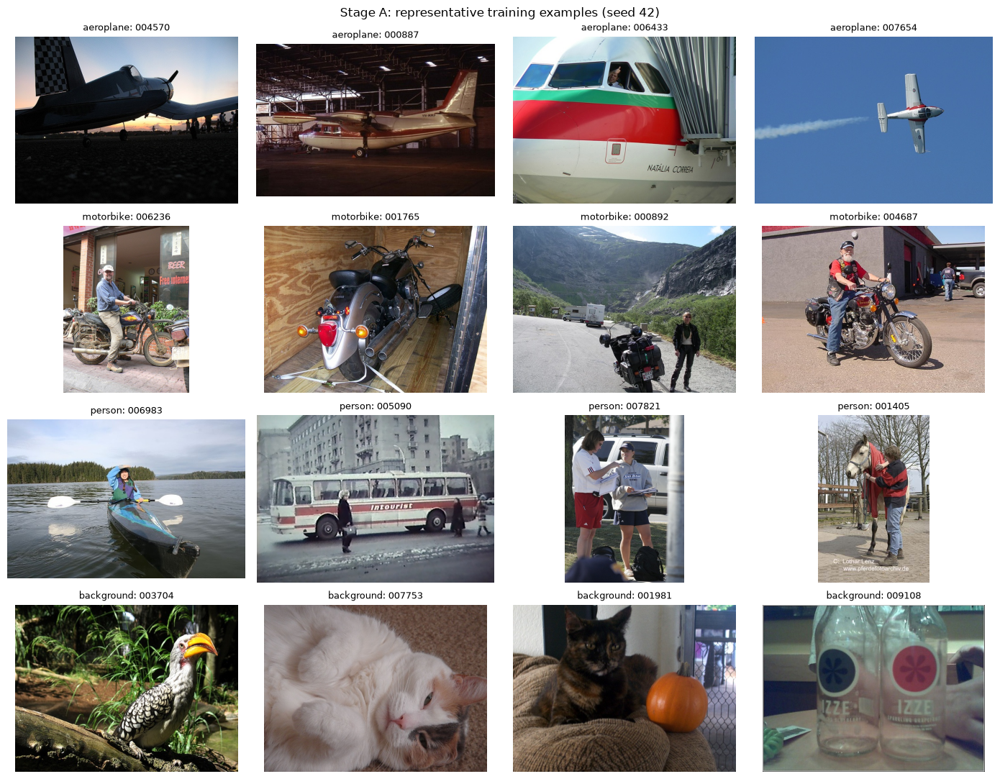

In [4]:
stage_a_rng = np.random.default_rng(SEED)
stage_a_categories = ("aeroplane", "motorbike", "person", "background")
fig, axes = plt.subplots(len(stage_a_categories), 4, figsize=(14, 11))
for row, cat in enumerate(stage_a_categories):
    archive = ROOT / "encodings/bovw_K512_C0" / f"{cat}_train.npz"
    with np.load(archive) as data:
        image_names = data["file_names"].astype(str)
    chosen = stage_a_rng.choice(image_names, size=min(4, len(image_names)), replace=False)
    for col, ax in enumerate(axes[row]):
        ax.axis("off")
        if col < len(chosen):
            image_path = ROOT / "images" / f"{chosen[col]}.jpg"
            ax.imshow(plt.imread(image_path))
            ax.set_title(f"{cat}: {chosen[col]}", fontsize=9)
fig.suptitle("Stage A: representative training examples (seed 42)")
fig.tight_layout()
plt.show()

In [5]:
stage_a_encoder_rows = []
for k in KS:
    encoder_path = ROOT / "encoders" / f"bovw_K{k}_C0.npz"
    with np.load(encoder_path, allow_pickle=True) as cfg:
        row = {"K": k, "encoder_KiB": encoder_path.stat().st_size / 1024}
        for key in ("num_words", "pca_dim", "seed", "num_images", "num_samples"):
            row[key] = cfg[key].item() if key in cfg else "not recorded"
        assert int(cfg["num_words"]) == k
    stage_a_encoder_rows.append(row)
display(pd.DataFrame(stage_a_encoder_rows))

,K,encoder_KiB,num_words,pca_dim,seed,num_images,num_samples
0,256,258.671875,256,0,42,799,319600
1,512,514.671875,512,0,42,799,319600
2,1024,1026.671875,1024,0,42,799,319600


,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,motorbike,bovw_K256_C0 | global | l2,256,0.41678,0.05935,0.35556,0.10982,0.00148,2.0,True
1,motorbike,bovw_K256_C0 | 2x2 | l2,1024,0.41471,0.08945,0.38333,0.26609,0.00446,8.0,True
2,motorbike,bovw_K512_C0 | global | l2,512,0.48469,0.07631,0.41667,0.14787,0.00179,4.0,True
3,motorbike,bovw_K512_C0 | 2x2 | l2,2048,0.44589,0.10181,0.35000,0.77714,0.00735,16.0,True
4,motorbike,bovw_K1024_C0 | global | l2,1024,0.49766,0.07338,0.40000,0.39121,0.00429,8.0,True
5,motorbike,bovw_K1024_C0 | 2x2 | l2,4096,0.44546,0.11146,0.38889,2.33106,0.01238,32.0,True


Selected by mean fold AP: bovw_K1024_C0 | global | l2


,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,motorbike,bovw_K1024_C0 | global | l2,1024,0.49766,0.07338,0.4,0.39121,0.00429,8.0,True


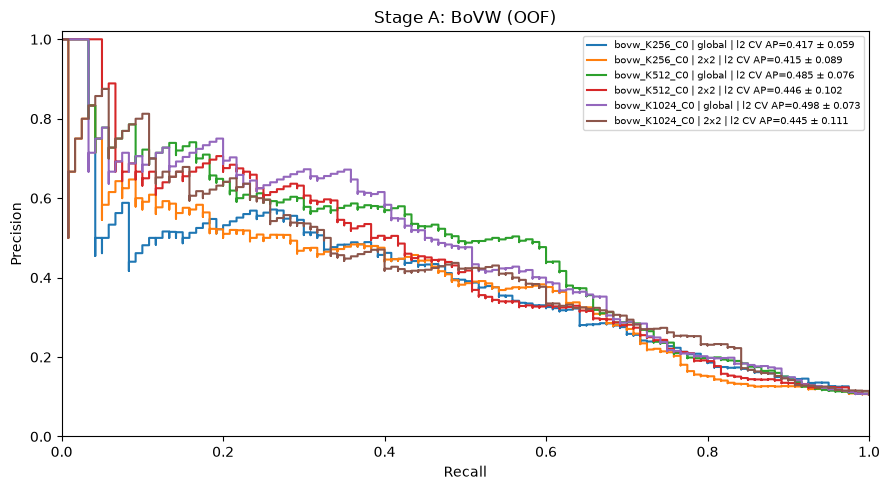

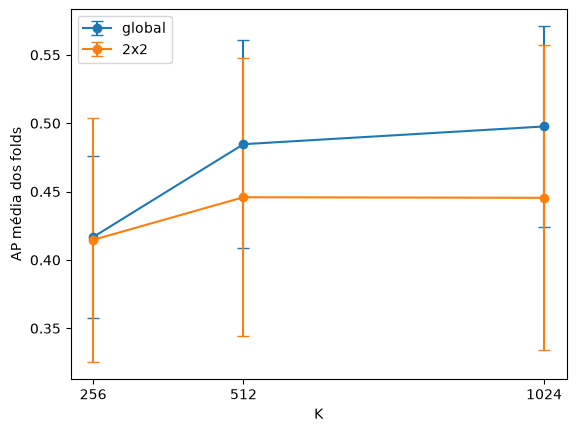

In [6]:
stage_a_runs = []
for k in KS:
    for spatial in (False, True):
        stage_a_runs.append(evaluate_cv(category, config(f'bovw_K{k}_C0', spatial)))
stage_a_results = table(stage_a_runs)
stage_a_best = choose_best(stage_a_runs)
bovw_cfg = stage_a_best['cfg'].copy()
encoding = bovw_cfg['encoding']
plot_cv(stage_a_runs, 'Stage A: BoVW')
fig, ax = plt.subplots()
for spatial in (False, True):
    runs = [r for r in stage_a_runs if r['cfg']['spatial'] == spatial]
    ax.errorbar(KS, [r['row']['cv_AP_mean'] for r in runs],
                yerr=[r['row']['cv_AP_std'] for r in runs], marker='o', capsize=4,
                label='2x2' if spatial else 'global')
ax.set(xlabel='K', ylabel='AP média dos folds', xticks=KS)
ax.legend(); plt.show()

## Stage B — Treino, ranking e palavras visuais com maior peso




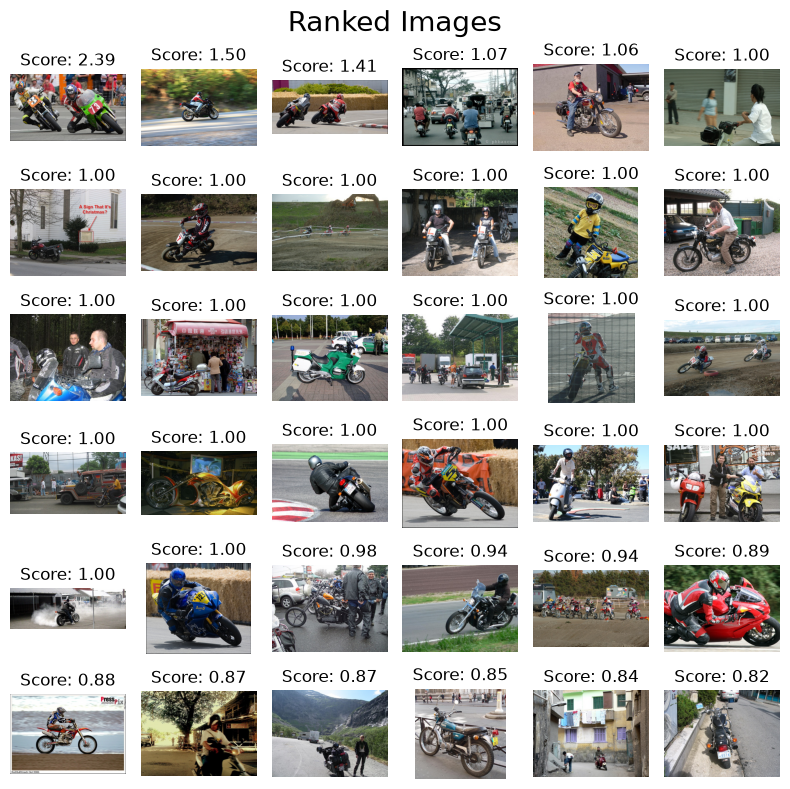

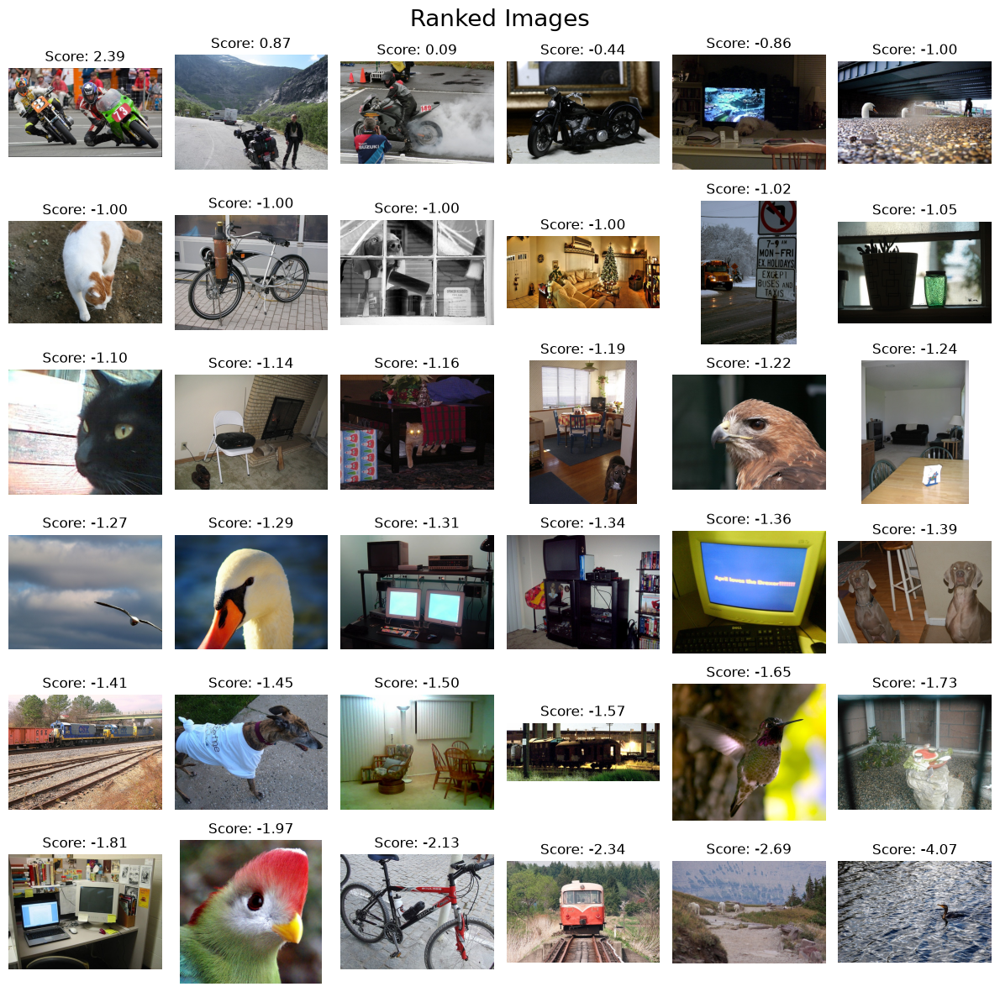

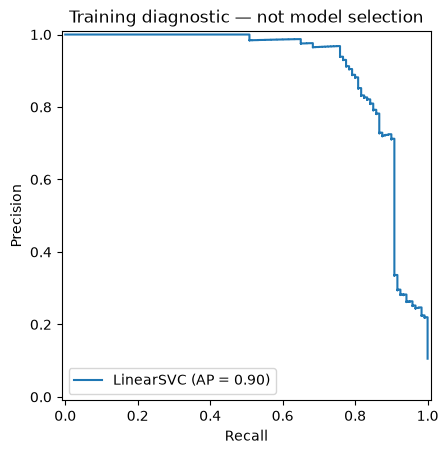

In [7]:
raw, labels, names = get_train(category, encoding)
histograms = transform(raw, bovw_cfg)
baseline_model, baseline_converged = fit_svm(histograms, labels)
if not baseline_converged: raise RuntimeError('Final full-train fit did not converge')
W, b = baseline_model.coef_[0], float(baseline_model.intercept_[0])
scores = baseline_model.decision_function(histograms)
full_paths = [str(ROOT/'images'/f'{name}.jpg') for name in names]
displayRankedImageList(scores, full_paths, uniform=False, figzize=(8,8))
displayRankedImageList(scores, full_paths, uniform=True, figzize=(12,12))
_ = displayPrecisionRecallCurve(labels, scores, title='Training diagnostic — not model selection')

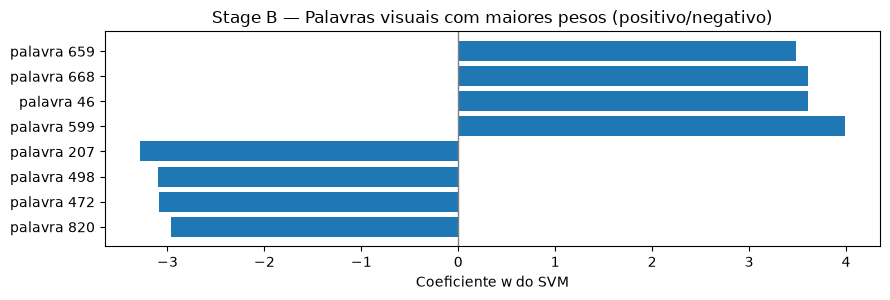

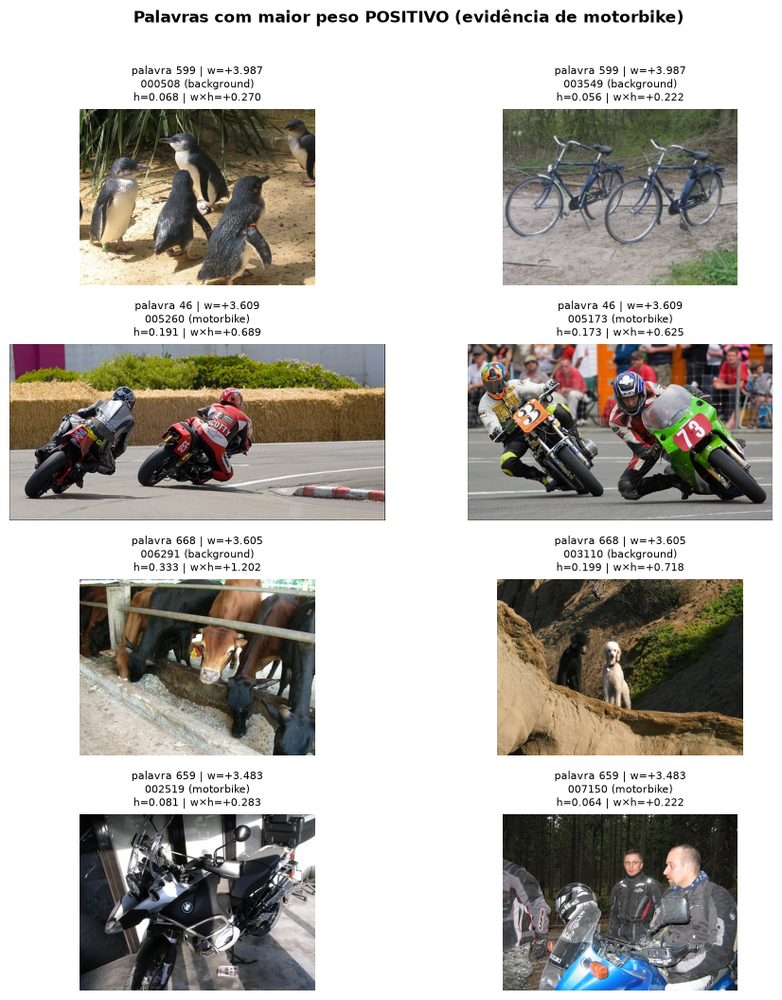

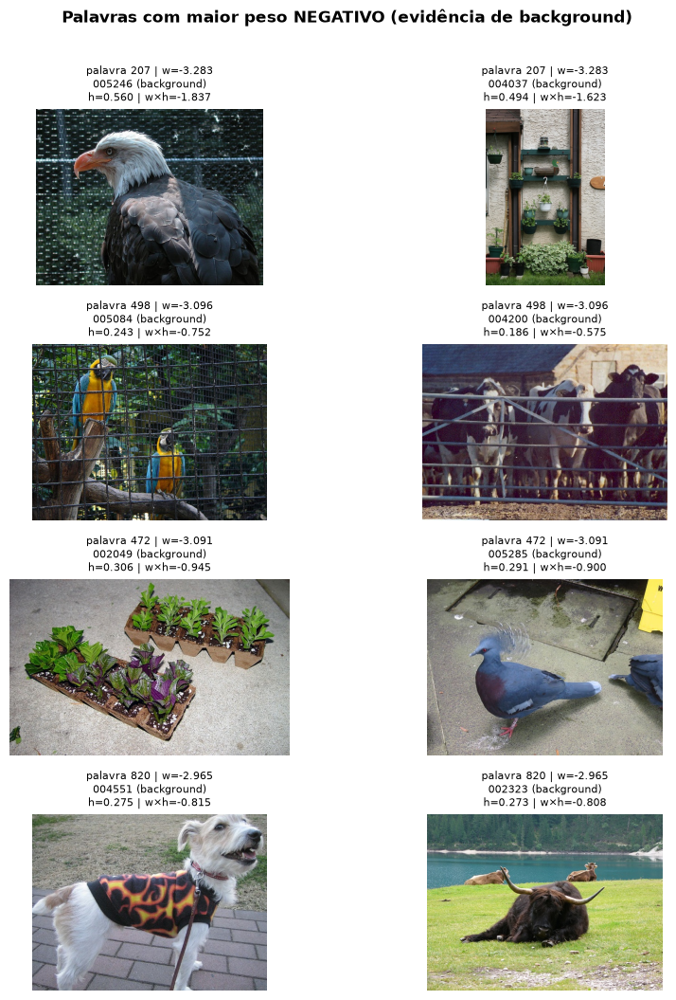

,sinal,palavra,quadrante,peso,imagem,classe,ativacao,contributo
0,positivo,599,-,3.9871,000508,background,0.0677,0.2699
1,positivo,599,-,3.9871,003549,background,0.0558,0.2223
2,positivo,46,-,3.6090,005260,motorbike,0.1909,0.6889
3,positivo,46,-,3.6090,005173,motorbike,0.1733,0.6254
4,positivo,668,-,3.6045,006291,background,0.3334,1.2017
5,positivo,668,-,3.6045,003110,background,0.1991,0.7176
6,positivo,659,-,3.4834,002519,motorbike,0.0812,0.2828
7,positivo,659,-,3.4834,007150,motorbike,0.0639,0.2224
8,negativo,207,-,-3.2834,005246,background,0.5596,-1.8373
9,negativo,207,-,-3.2834,004037,background,0.4943,-1.6231


Nota: as imagens ilustram onde as palavras de maior peso aparecem com maior ativação no histograma. BoVW global não permite localizar as regiões SIFT na imagem; os painéis não são mapas de saliência.


In [ ]:
TOP_WORDS = 4          # 4 palavras positivas e 4 negativas
EXAMPLES_PER_WORD = 2  # 2 imagens por palavra
K_WORDS = int(encoding.split("_K")[1].split("_")[0])
assert histograms.shape[1] == len(W)


def word_label(j):
    j = int(j)
    return (f"palavra {j % K_WORDS} (quadrante {j // K_WORDS + 1})"
            if bovw_cfg['spatial'] else f"palavra {j}")


def top_weighted_word_examples(sign, n_words=TOP_WORDS, n_examples=EXAMPLES_PER_WORD):
    """Imagens mais ativadas por palavras de maior peso positivo/negativo.

    O modelo é o SVM ajustado ao treino na célula anterior; não se usam
    labels/validação/teste para escolher palavras ou exemplos.
    """
    has_word = np.any(histograms > 0, axis=0)
    candidates = np.flatnonzero(has_word & ((W > 0) if sign > 0 else (W < 0)))
    if not len(candidates):
        print('Não existem palavras com o sinal pedido e ativação no treino.')
        return []
    # Ordenação por peso SVM (não pelo score total da imagem).
    order = np.argsort(-W[candidates] if sign > 0 else W[candidates], kind='stable')
    selected = candidates[order[:n_words]]

    title = ('Palavras com maior peso POSITIVO (evidência de motorbike)'
             if sign > 0 else
             'Palavras com maior peso NEGATIVO (evidência de background)')
    fig, axes = plt.subplots(len(selected), n_examples,
                             figsize=(4.6*n_examples, 2.6*len(selected)),
                             squeeze=False)
    rows = []
    for row, j in enumerate(selected):
        present = np.flatnonzero(histograms[:, j] > 0)
        # Para w_j fixo, maior h_j significa maior contribuição em módulo.
        ranked = present[np.argsort(-histograms[present, j], kind='stable')]
        for col in range(n_examples):
            ax = axes[row, col]
            ax.axis('off')
            if col >= len(ranked):
                continue
            idx = int(ranked[col])
            image_path = ROOT / 'images' / f'{names[idx]}.jpg'
            if image_path.exists():
                ax.imshow(plt.imread(str(image_path)))
            else:
                ax.text(.5, .5, f'Imagem não encontrada:\n{image_path.name}',
                        ha='center', va='center', transform=ax.transAxes)
            klass = 'motorbike' if labels[idx] == 1 else 'background'
            freq = float(histograms[idx, j])
            contribution = float(W[j] * freq)
            ax.set_title(f'{word_label(j)} | w={W[j]:+.3f}\n'
                         f'{str(names[idx])[:25]} ({klass})\n'
                         f'h={freq:.3f} | w×h={contribution:+.3f}', fontsize=8)
            rows.append(dict(sinal='positivo' if sign > 0 else 'negativo',
                             palavra=int(j % K_WORDS),
                             quadrante=int(j // K_WORDS + 1) if bovw_cfg['spatial'] else '-',
                             peso=float(W[j]), imagem=str(names[idx]),
                             classe=klass, ativacao=freq, contributo=contribution))
    fig.suptitle(title, fontsize=12, fontweight='bold', y=1.01)
    fig.tight_layout()
    plt.show()
    return rows


# Gráfico dos coeficientes do classificador: palavras, não imagens.
active = np.any(histograms > 0, axis=0)
positive = np.flatnonzero(active & (W > 0))
negative = np.flatnonzero(active & (W < 0))
positive = positive[np.argsort(-W[positive], kind='stable')[:TOP_WORDS]]
negative = negative[np.argsort(W[negative], kind='stable')[:TOP_WORDS]]
word_indices = np.r_[negative[::-1], positive]
fig, ax = plt.subplots(figsize=(9, 3.1))
ax.barh(np.arange(len(word_indices)), W[word_indices])
ax.set_yticks(np.arange(len(word_indices)),
              [word_label(j) for j in word_indices])
ax.axvline(0, linewidth=1, color='gray')
ax.set(xlabel='Coeficiente w do SVM',
       title='Stage B — Palavras visuais com maiores pesos (positivo/negativo)')
fig.tight_layout()
plt.show()

# Imagens exemplificativas em que estas palavras mais contribuem.
word_rows = (top_weighted_word_examples(+1) +
             top_weighted_word_examples(-1))
stage_b_visual_words = pd.DataFrame(word_rows)
display(stage_b_visual_words.round(4))
print('Nota: as imagens ilustram onde as palavras de maior peso aparecem'
      ' com maior ativação no histograma. BoVW global não permite localizar'
      ' as regiões SIFT na imagem; os painéis não são mapas de saliência.')


## Stage C — Recuperação out-of-fold


Stage C: motorbike | OOF; mean fold AP: 0.4976562486393655


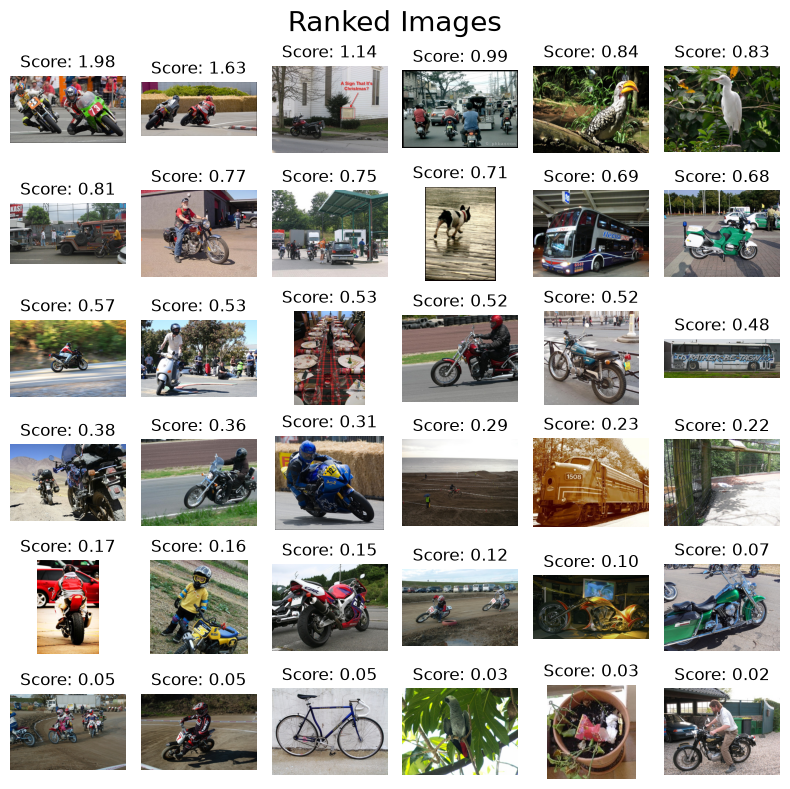

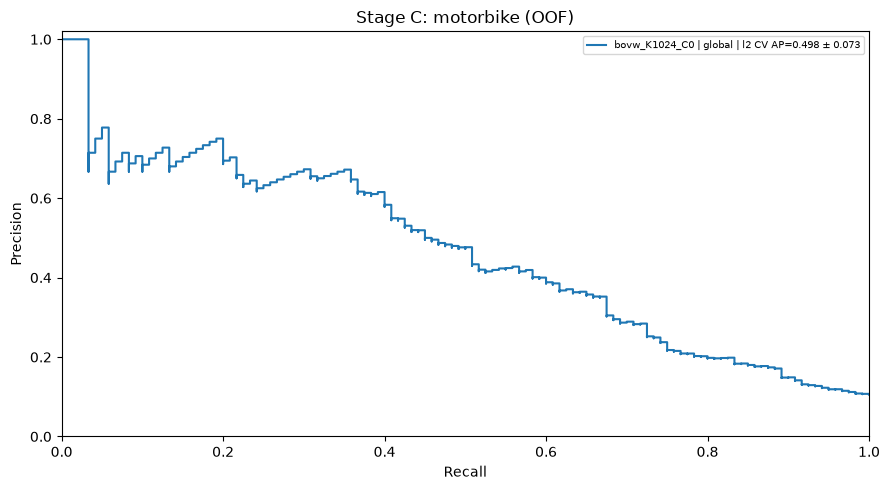

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[1008   11]
 [  94   26]]
Precisão: 0.7027
Recall: 0.2167


,fold,AP,P36,fit_s,score_ms_image,converged
0,1,0.44085,0.38889,0.28716,0.00455,True
1,2,0.44612,0.30556,0.34987,0.00466,True
2,3,0.44552,0.44444,0.52014,0.00426,True
3,4,0.57244,0.38889,0.45376,0.00400,True
4,5,0.58335,0.47222,0.34511,0.00397,True


In [9]:
show_oof(stage_a_best, 'Stage C: motorbike')
display(stage_a_best['folds'].round(5))

## Stage D — Outras categorias


,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,motorbike,bovw_K1024_C0 | global | l2,1024,0.49766,0.07338,0.40000,0.39121,0.00429,8.0,True
1,aeroplane,bovw_K1024_C0 | global | l2,1024,0.50791,0.10947,0.46667,0.66355,0.00448,8.0,True
2,person,bovw_K1024_C0 | global | l2,1024,0.72366,0.01845,0.81667,0.83441,0.00330,8.0,True
3,horse,bovw_K1024_C0 | global | l2,1024,0.50315,0.07859,0.42778,0.63685,0.00373,8.0,True
4,car,bovw_K1024_C0 | global | l2,1024,0.66972,0.02603,0.72222,1.22925,0.00343,8.0,True


mAP das médias CV: 0.5804173741311255
motorbike | OOF; mean fold AP: 0.4976562486393655


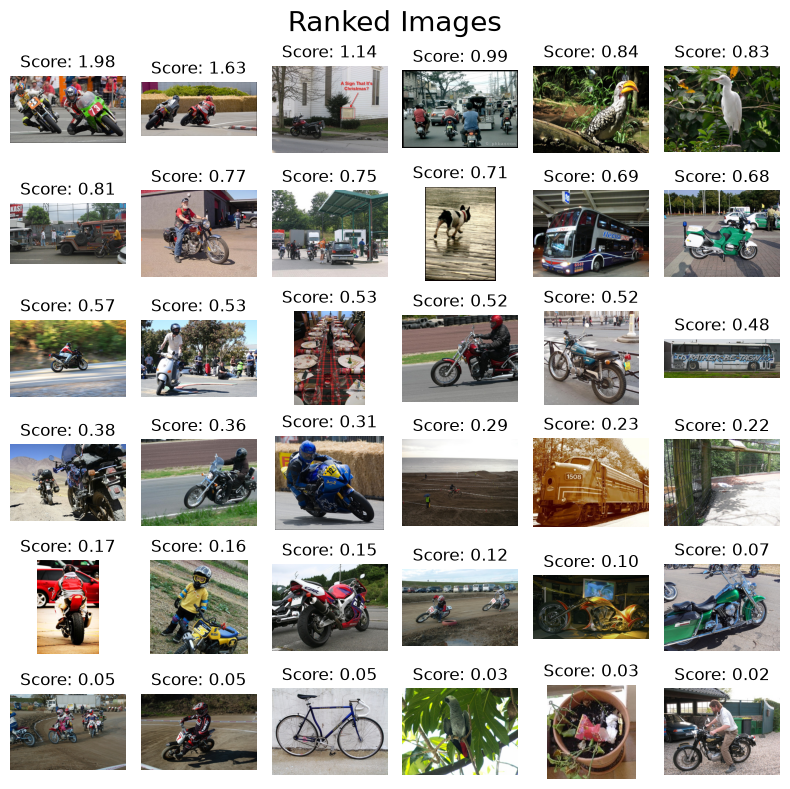

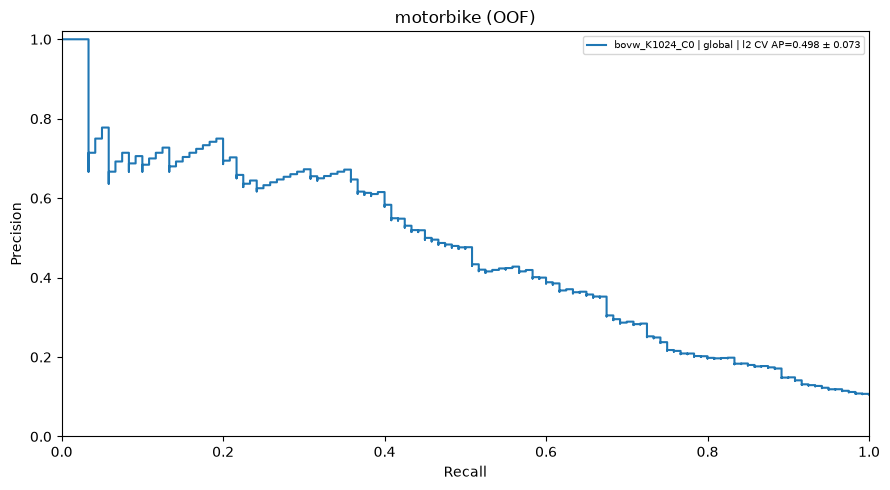

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[1008   11]
 [  94   26]]
Precisão: 0.7027
Recall: 0.2167
aeroplane | OOF; mean fold AP: 0.5079053984938617


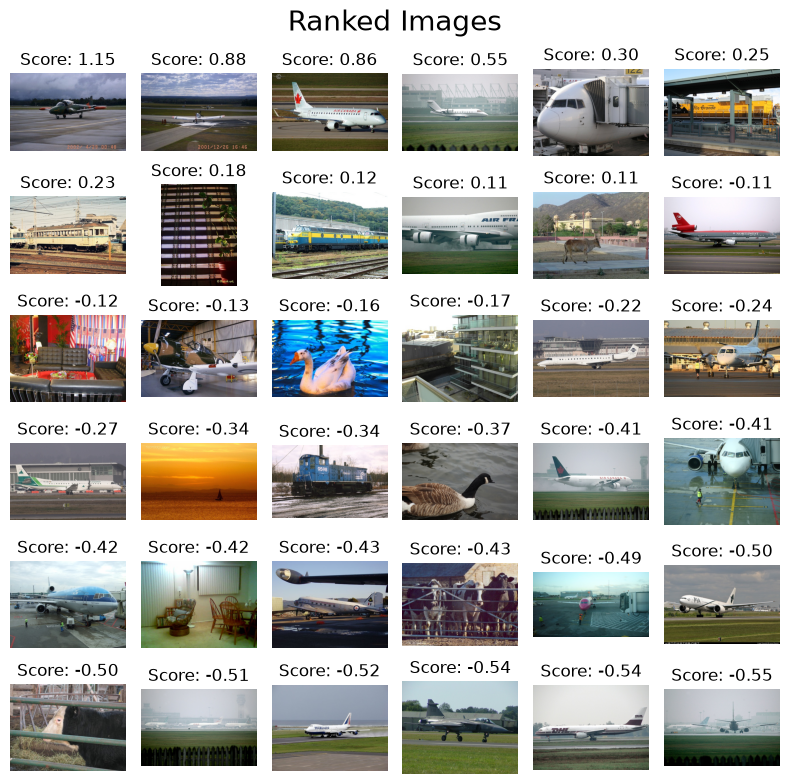

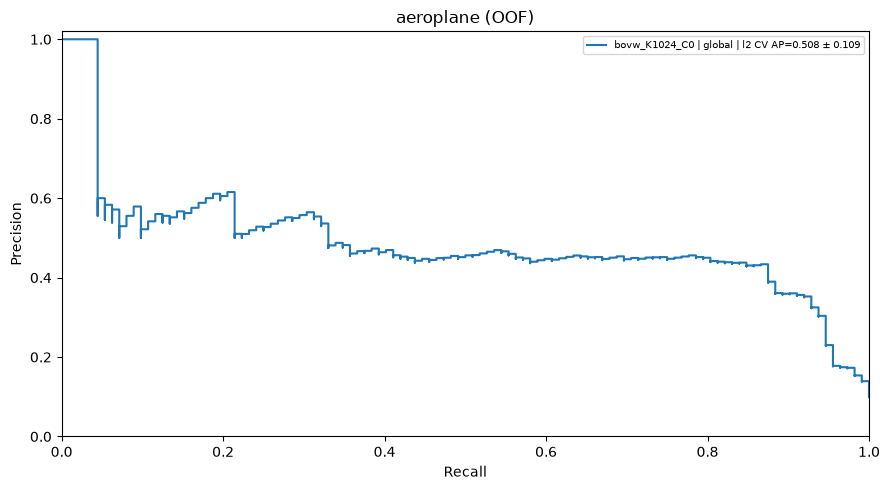

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[1014    5]
 [ 106    6]]
Precisão: 0.5455
Recall: 0.0536
person | OOF; mean fold AP: 0.7236587805834022


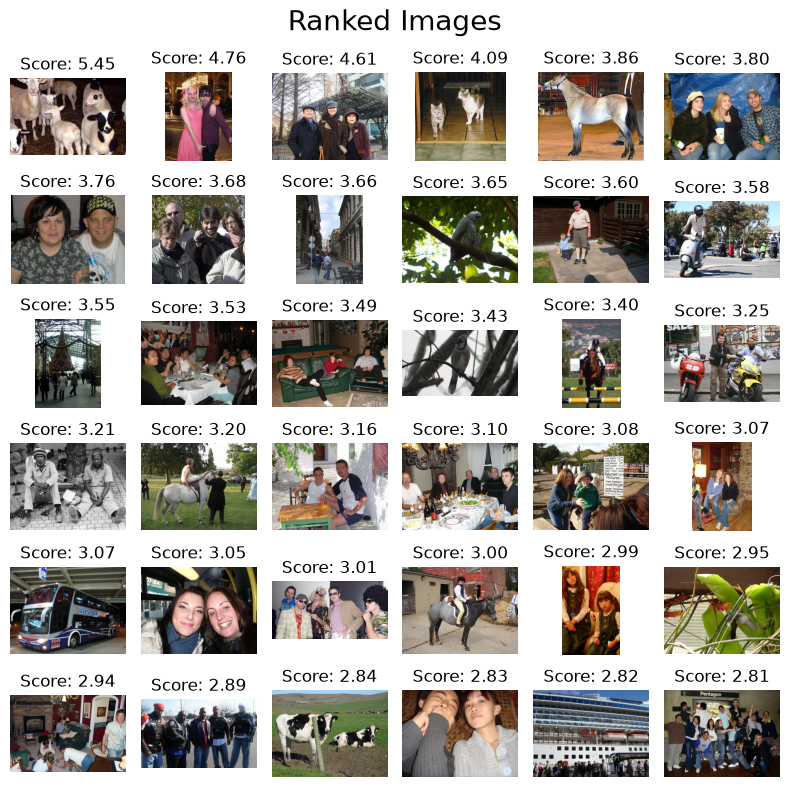

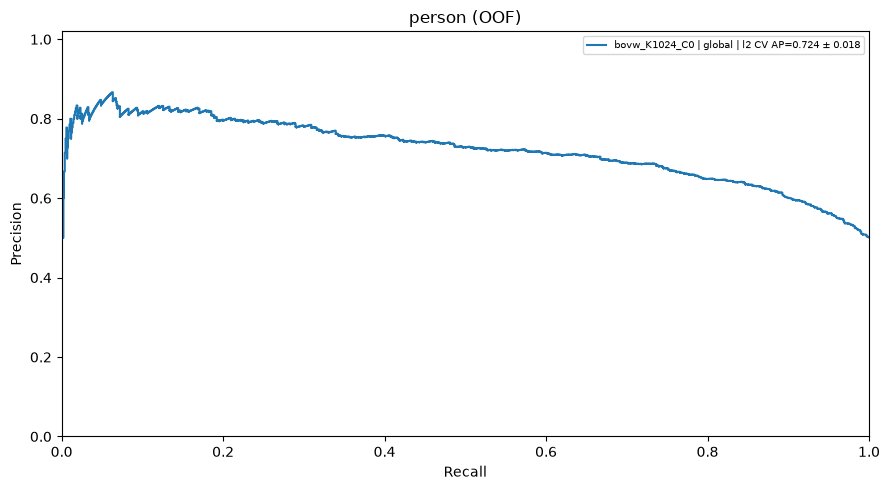

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[795 224]
 [447 578]]
Precisão: 0.7207
Recall: 0.5639
horse | OOF; mean fold AP: 0.5031478409876927


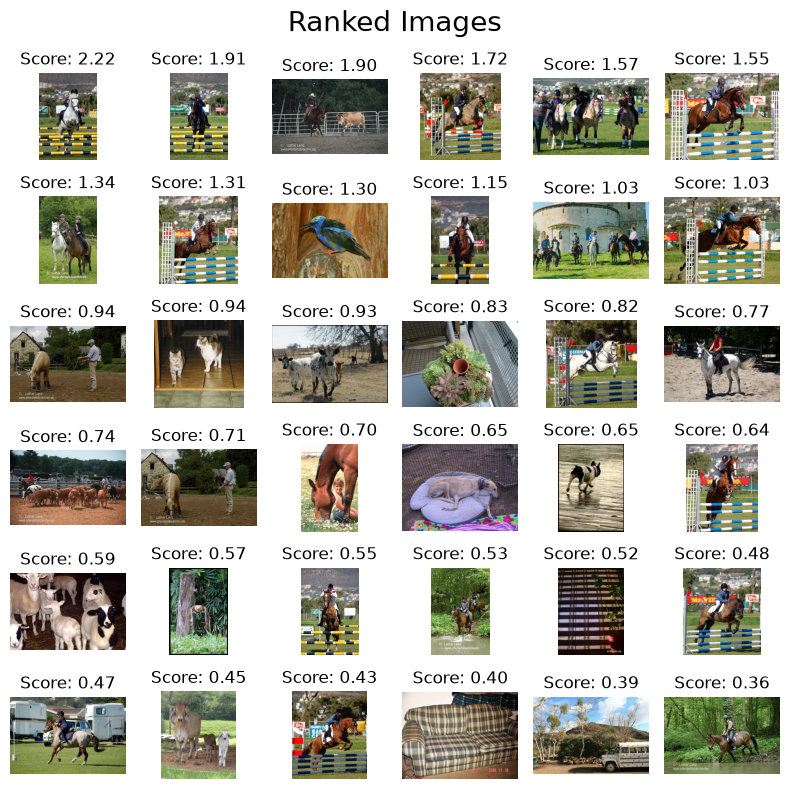

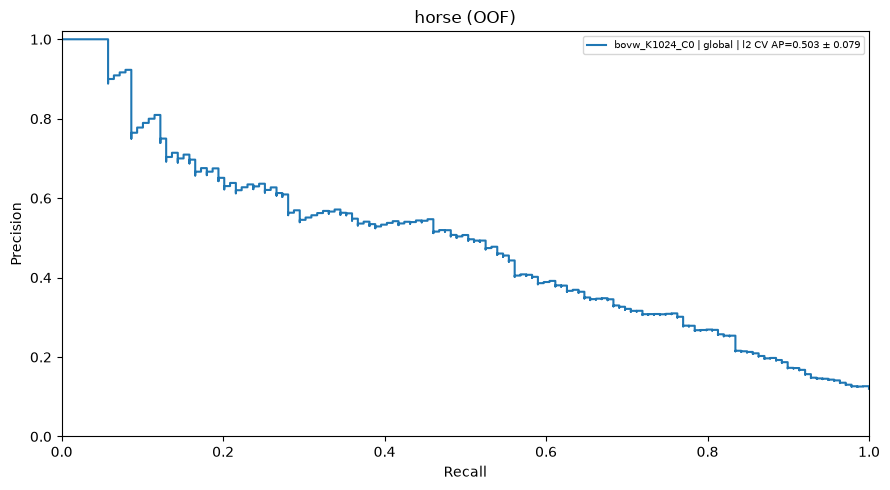

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[987  32]
 [ 98  41]]
Precisão: 0.5616
Recall: 0.2950
car | OOF; mean fold AP: 0.6697186019513055


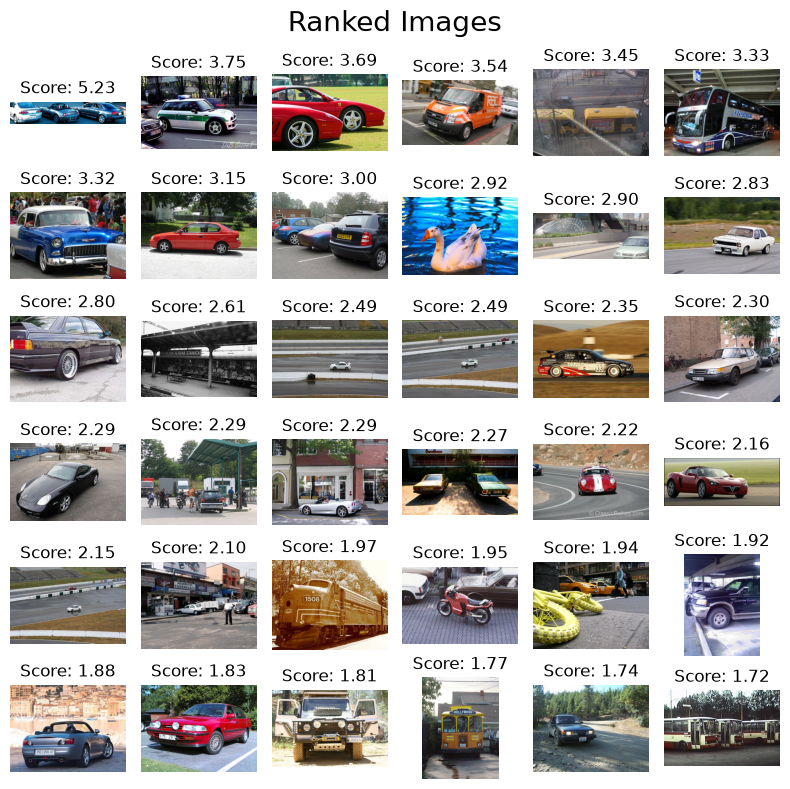

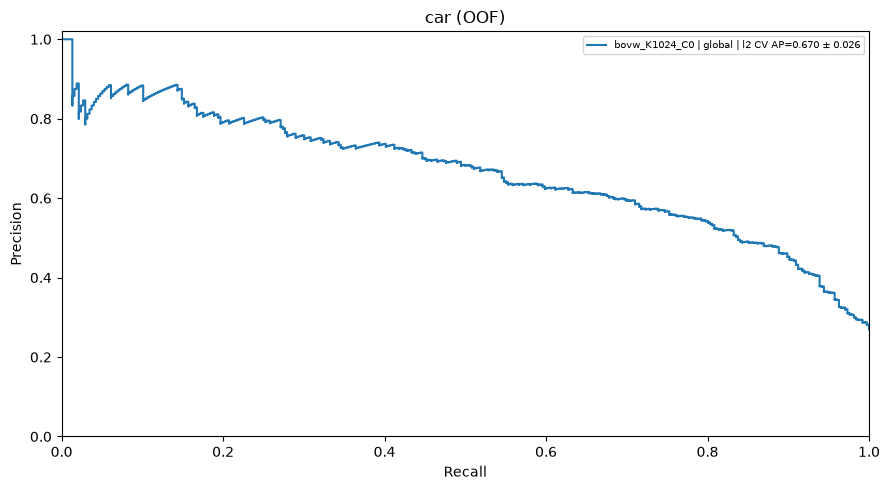

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[954  65]
 [212 164]]
Precisão: 0.7162
Recall: 0.4362


In [10]:
stage_d_runs = [evaluate_cv(cat, bovw_cfg) for cat in CATEGORIES]
stage_d_results = table(stage_d_runs)
print('mAP das médias CV:', stage_d_results.cv_AP_mean.mean())
for r in stage_d_runs: show_oof(r, r['row']['category'])

## Stage E — Normalização e informação espacial


,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,motorbike,bovw_K1024_C0 | global | none,1024,0.44144,0.07887,0.37222,37.87262,0.00420,8.0,False
1,motorbike,bovw_K1024_C0 | global | l1,1024,0.41258,0.10453,0.38333,2.76648,0.00441,8.0,True
2,motorbike,bovw_K1024_C0 | global | l2,1024,0.49766,0.07338,0.40000,0.39121,0.00429,8.0,True
3,motorbike,bovw_K1024_C0 | 2x2 | none,4096,0.42260,0.09122,0.38889,35.11144,0.01403,32.0,True
4,motorbike,bovw_K1024_C0 | 2x2 | l1,4096,0.39364,0.09042,0.36111,12.06242,0.01226,32.0,True
5,motorbike,bovw_K1024_C0 | 2x2 | l2,4096,0.44546,0.11146,0.38889,2.33106,0.01238,32.0,True


Selected by mean fold AP: bovw_K1024_C0 | global | l2


,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,motorbike,bovw_K1024_C0 | global | l2,1024,0.49766,0.07338,0.4,0.39121,0.00429,8.0,True


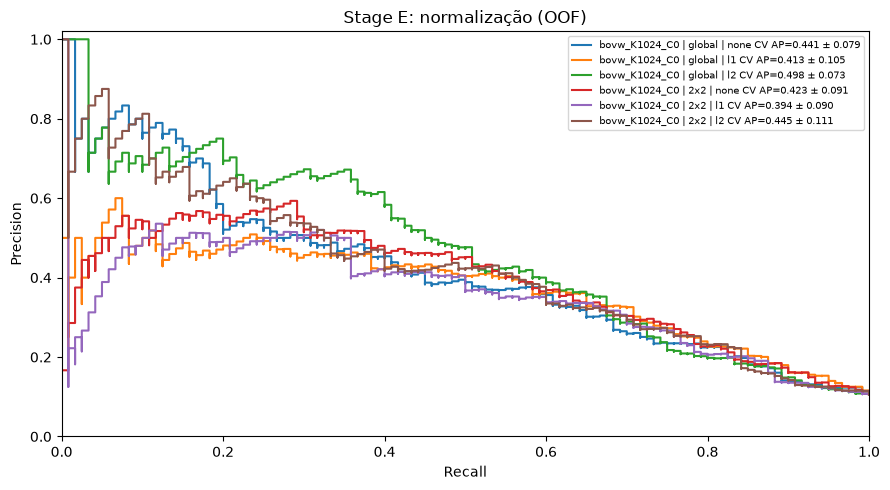

In [11]:
stage_e_runs = [evaluate_cv(category, config(encoding, spatial, norm))
                for spatial in (False, True) for norm in ('none','l1','l2')]
stage_e_results = table(stage_e_runs)
stage_e_best = choose_best(stage_e_runs)
plot_cv(stage_e_runs, 'Stage E: normalização')

## Stage F — Hellinger


,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,motorbike,bovw_K1024_C0 | global | l2,1024,0.49766,0.07338,0.40000,0.39121,0.00429,8.0,True
1,motorbike,bovw_K1024_C0 | global | sqrt + none,1024,0.51844,0.04479,0.44444,0.28825,0.00383,8.0,True
2,motorbike,bovw_K1024_C0 | global | sqrt + l1,1024,0.51295,0.03521,0.43333,6.96778,0.00382,8.0,True
3,motorbike,bovw_K1024_C0 | global | sqrt + l2,1024,0.59668,0.04978,0.44444,0.12249,0.00388,8.0,True


Selected by mean fold AP: bovw_K1024_C0 | global | sqrt + l2


,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,motorbike,bovw_K1024_C0 | global | sqrt + l2,1024,0.59668,0.04978,0.44444,0.12249,0.00388,8.0,True


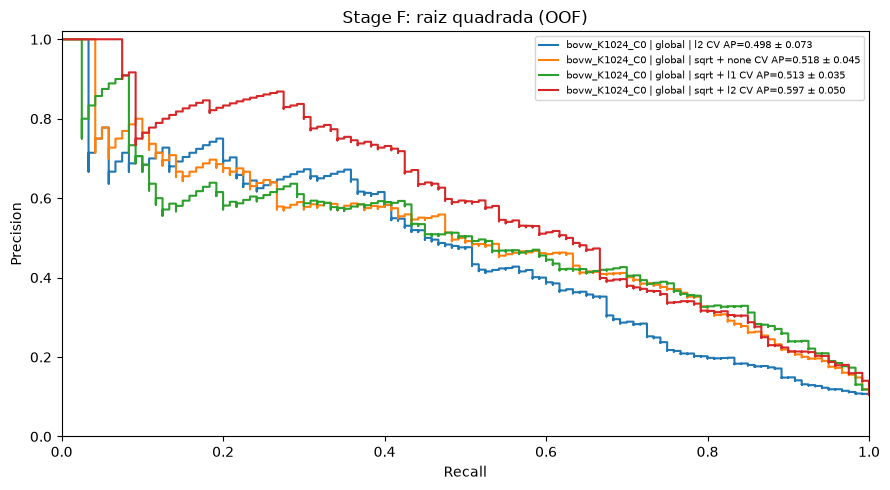

Selected by mean fold AP: bovw_K1024_C0 | global | sqrt + l2


,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,motorbike,bovw_K1024_C0 | global | sqrt + l2,1024,0.59668,0.04978,0.44444,0.12249,0.00388,8.0,True


In [12]:
chosen_spatial = stage_e_best['cfg']['spatial']
linear_cfg = config(encoding, chosen_spatial, 'l2')
hellinger_cfg = config(encoding, chosen_spatial, 'l2', True)
stage_f_runs = [evaluate_cv(category, linear_cfg)] + [
    evaluate_cv(category, config(encoding, chosen_spatial, norm, True))
    for norm in ('none','l1','l2')]
stage_f_results = table(stage_f_runs)
stage_f_best = choose_best(stage_f_runs)
plot_cv(stage_f_runs, 'Stage F: raiz quadrada')
# Melhor candidato BoVW efetivamente avaliado nas stages A/E/F.
part1_best = choose_best(stage_a_runs + stage_e_runs + stage_f_runs)

## Stage G — Curvas de aprendizagem dentro da cross-validation


,method,fraction,seed,cv_AP_mean,cv_AP_std_folds,n_train,n_positive,converged
0,Hellinger + L2,0.10,42,0.26885,0.09358,92.0,10.0,True
1,Hellinger + L2,0.10,43,0.34174,0.10777,92.0,10.0,True
2,Hellinger + L2,0.10,44,0.29799,0.11445,92.0,10.0,True
3,Hellinger + L2,0.25,42,0.40634,0.05030,228.0,24.0,True
4,Hellinger + L2,0.25,43,0.45195,0.10310,228.0,24.0,True
5,Hellinger + L2,0.25,44,0.49035,0.04645,228.0,24.0,True
6,Hellinger + L2,0.50,42,0.49177,0.03381,456.0,48.0,True
7,Hellinger + L2,0.50,43,0.54262,0.02757,456.0,48.0,True
8,Hellinger + L2,0.50,44,0.60275,0.10525,456.0,48.0,True
9,Hellinger + L2,1.00,42,0.59668,0.04978,911.2,96.0,True


,method,fraction,cv_AP_mean,std_seeds,n_train,n_positive,converged
0,Hellinger + L2,0.10,0.30286,0.03668,92.0,10.0,True
1,Hellinger + L2,0.25,0.44955,0.04205,228.0,24.0,True
2,Hellinger + L2,0.50,0.54571,0.05555,456.0,48.0,True
3,Hellinger + L2,1.00,0.59668,0.00000,911.2,96.0,True
4,Linear + L2,0.10,0.26682,0.02009,92.0,10.0,True
5,Linear + L2,0.25,0.35416,0.02007,228.0,24.0,True
6,Linear + L2,0.50,0.40376,0.04525,456.0,48.0,True
7,Linear + L2,1.00,0.49766,0.00000,911.2,96.0,True


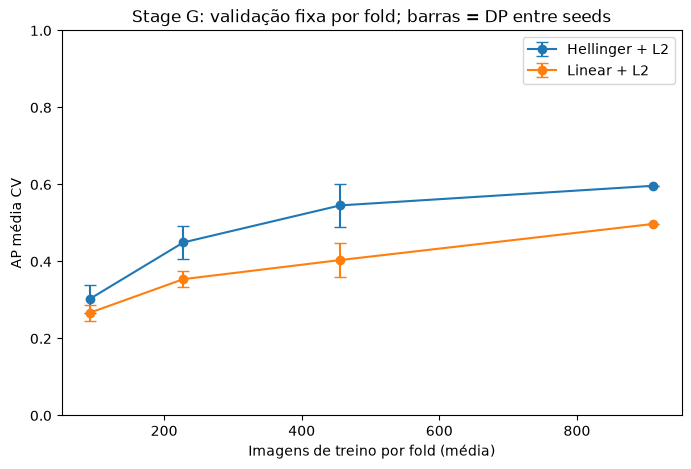

In [13]:
raw, y, _ = get_train(category, encoding)
features = {'Linear + L2': transform(raw, linear_cfg),
            'Hellinger + L2': transform(raw, hellinger_cfg)}
rows = []
for seed in (42,43,44):
    for fold, (tr, va) in enumerate(_folds[category], 1):
        rng = np.random.default_rng(seed + 1000*fold)
        groups = [rng.permutation(tr[y[tr] == label]) for label in (-1,1)]
        for fraction in (.1,.25,.5,1.):
            selected = np.concatenate([g[:max(1,int(np.ceil(fraction*len(g))))] for g in groups])
            assert not np.intersect1d(selected, va).size
            for method, x in features.items():
                model, converged = fit_svm(x[selected], y[selected])
                rows.append(dict(seed=seed, fold=fold, fraction=fraction, method=method,
                    n_train=len(selected), n_positive=int((y[selected]==1).sum()),
                    AP=average_precision_score(y[va], model.decision_function(x[va])),
                    converged=converged))
stage_g_results = pd.DataFrame(rows)
stage_g_per_seed = stage_g_results.groupby(['method','fraction','seed'], as_index=False).agg(
    cv_AP_mean=('AP','mean'), cv_AP_std_folds=('AP','std'), n_train=('n_train','mean'),
    n_positive=('n_positive','mean'), converged=('converged','all'))
stage_g_summary = stage_g_per_seed.groupby(['method','fraction'], as_index=False).agg(
    cv_AP_mean=('cv_AP_mean','mean'), std_seeds=('cv_AP_mean','std'),
    n_train=('n_train','mean'), n_positive=('n_positive','mean'), converged=('converged','all'))
display(stage_g_per_seed.round(5)); display(stage_g_summary.round(5))
fig, ax = plt.subplots(figsize=(8,5))
for method, group in stage_g_summary.groupby('method'):
    ax.errorbar(group.n_train, group.cv_AP_mean, yerr=group.std_seeds,
                marker='o', capsize=4, label=method)
ax.set(xlabel='Imagens de treino por fold (média)', ylabel='AP média CV', ylim=(0,1),
       title='Stage G: validação fixa por fold; barras = DP entre seeds')
ax.legend(); plt.show()

# Part 2 — VLAD e Fisher Vectors


## Stage H — VLAD

,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,motorbike,vlad_K32_C80 | 2x2 | l2,10240,0.5786,0.12945,0.43889,0.82468,0.02909,80.0,True


Stage H: VLAD | OOF; mean fold AP: 0.5786036319808893


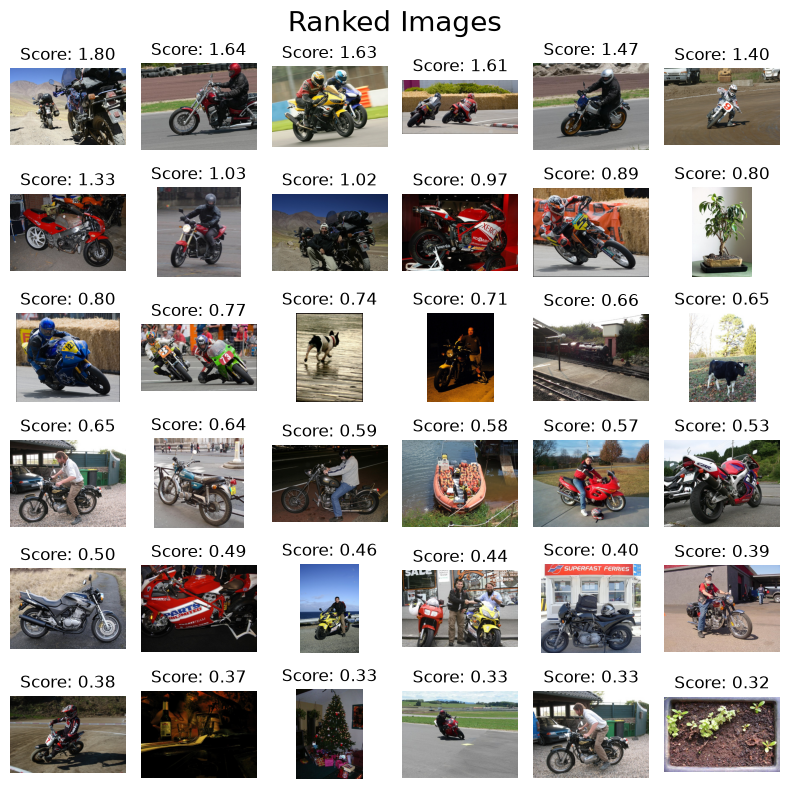

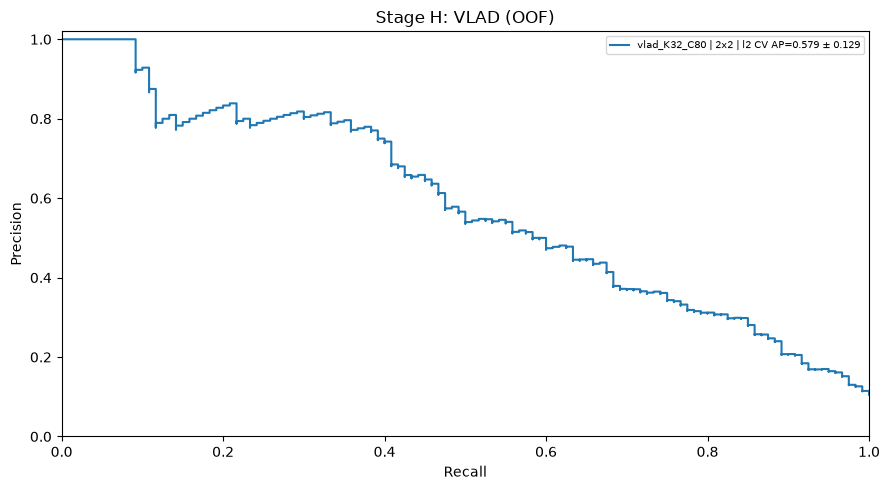

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[992  27]
 [ 68  52]]
Precisão: 0.6582
Recall: 0.4333


In [14]:
vlad_cfg = config('vlad_K32_C80')
stage_h_run = evaluate_cv(category, vlad_cfg)
table([stage_h_run])
show_oof(stage_h_run, 'Stage H: VLAD')

## Stage I — Fisher Vector

,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,motorbike,fv_K32_C80 | 2x2 | l2,20608,0.59065,0.09197,0.42222,11.88798,0.05168,161.0,True


Stage I: Fisher Vector | OOF; mean fold AP: 0.5906541926575868


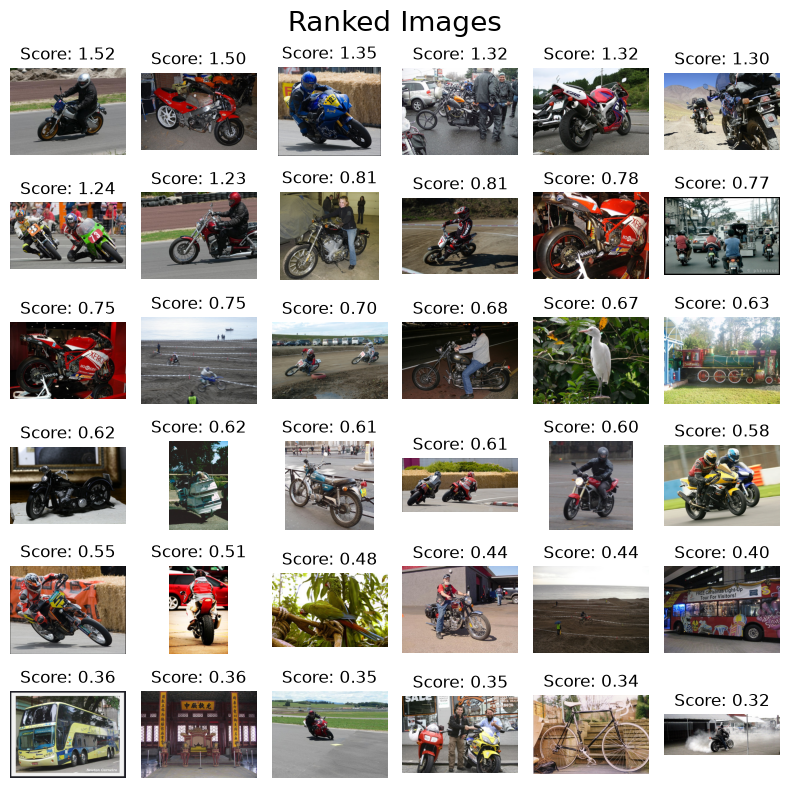

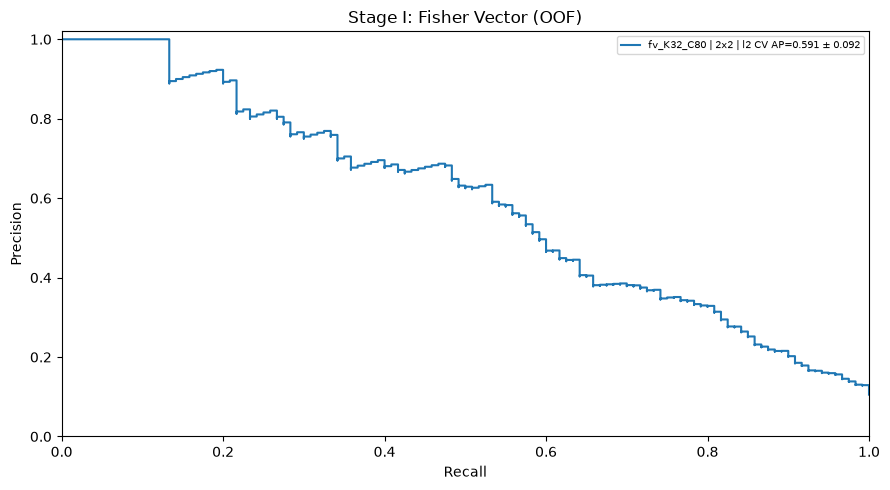

Limiar: 0; ordem: [-1, +1]
Matriz de confusão:
 [[998  21]
 [ 73  47]]
Precisão: 0.6912
Recall: 0.3917


In [15]:
fv_cfg = config('fv_K32_C80')
stage_i_run = evaluate_cv(category, fv_cfg)
table([stage_i_run])
show_oof(stage_i_run, 'Stage I: Fisher Vector')

## Comparação controlada e seleção final por categoria


In [16]:
controlled_cfgs = [config('bovw_K512_C0'), vlad_cfg, fv_cfg]
controlled_runs = [evaluate_cv(cat, cfg) for cat in CATEGORIES for cfg in controlled_cfgs]
comparison = table(controlled_runs)
map_table = comparison.groupby('configuration', as_index=False).agg(
    cv_mAP=('cv_AP_mean','mean'), mean_fit_s=('fit_s_mean','mean'),
    mean_scoring_ms_image=('scoring_ms_image_mean','mean'), converged=('converged','all'))
display(map_table.round(5))
final_selected = {}
for cat in CATEGORIES:
    candidates = [r for r in controlled_runs if r['row']['category'] == cat]
    if cat == category:
        candidates += stage_a_runs + stage_e_runs + stage_f_runs
    else:
        candidates.append(evaluate_cv(cat, part1_best['cfg']))
    final_selected[cat] = choose_best(candidates)

,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,motorbike,bovw_K512_C0 | 2x2 | l2,2048,0.44589,0.10181,0.35000,0.77714,0.00735,16.0,True
1,motorbike,vlad_K32_C80 | 2x2 | l2,10240,0.57860,0.12945,0.43889,0.82468,0.02909,80.0,True
2,motorbike,fv_K32_C80 | 2x2 | l2,20608,0.59065,0.09197,0.42222,11.88798,0.05168,161.0,True
3,aeroplane,bovw_K512_C0 | 2x2 | l2,2048,0.59445,0.07750,0.49444,0.33424,0.00763,16.0,True
4,aeroplane,vlad_K32_C80 | 2x2 | l2,10240,0.74170,0.08882,0.50556,0.62547,0.03188,80.0,True
5,aeroplane,fv_K32_C80 | 2x2 | l2,20608,0.75740,0.09815,0.46667,3.46367,0.05151,161.0,True
6,person,bovw_K512_C0 | 2x2 | l2,2048,0.71486,0.01616,0.77778,1.32338,0.00603,16.0,True
7,person,vlad_K32_C80 | 2x2 | l2,10240,0.77773,0.02539,0.92778,4.54850,0.02986,80.0,True
8,person,fv_K32_C80 | 2x2 | l2,20608,0.79807,0.02196,0.94444,24.84621,0.05318,161.0,True
9,horse,bovw_K512_C0 | 2x2 | l2,2048,0.56841,0.08151,0.44444,0.69433,0.00689,16.0,True


,configuration,cv_mAP,mean_fit_s,mean_scoring_ms_image,converged
0,bovw_K512_C0 | 2x2 | l2,0.60236,1.01424,0.00692,True
1,fv_K32_C80 | 2x2 | l2,0.71603,11.87223,0.05300,True
2,vlad_K32_C80 | 2x2 | l2,0.80204,1.55105,0.02932,True


Selected by mean fold AP: bovw_K1024_C0 | global | sqrt + l2


,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,motorbike,bovw_K1024_C0 | global | sqrt + l2,1024,0.59668,0.04978,0.44444,0.12249,0.00388,8.0,True


Selected by mean fold AP: bovw_K1024_C0 | global | sqrt + l2


,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,aeroplane,bovw_K1024_C0 | global | sqrt + l2,1024,0.78231,0.08829,0.52222,0.09044,0.00363,8.0,True


... (2 outputs left out)

Selected by mean fold AP: vlad_K32_C80 | 2x2 | l2


,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,horse,vlad_K32_C80 | 2x2 | l2,10240,0.93432,0.04291,0.70556,0.61305,0.02591,80.0,True


Selected by mean fold AP: vlad_K32_C80 | 2x2 | l2


,category,configuration,dimensions,cv_AP_mean,cv_AP_std,cv_P36_mean,fit_s_mean,scoring_ms_image_mean,feature_KiB,converged
0,car,vlad_K32_C80 | 2x2 | l2,10240,0.97787,0.00468,1.0,1.14356,0.02986,80.0,True


## Avaliação final opcional em `val` — não participa nas comparações


In [17]:
RUN_FINAL_EVALUATION = False
if RUN_FINAL_EVALUATION:
    final_rows = []
    for cat, selected in final_selected.items():
        cfg = selected['cfg']
        raw, y, train_names = get_train(cat, cfg['encoding'])
        model, converged = fit_svm(transform(raw, cfg), y)
        if not converged: raise RuntimeError(f'Full-train model did not converge: {cat}')
        val_raw, val_y, val_names = loadEncodingSubset(cat, cfg['encoding'], subset='val', root_dir=str(ROOT))
        if set(train_names).intersection(np.asarray(val_names).astype(str)):
            raise ValueError('Overlap between train and final evaluation')
        final_scores = model.decision_function(transform(val_raw, cfg))
        final_rows.append(dict(category=cat, configuration=config_name(cfg),
                              final_val_AP=average_precision_score(val_y, final_scores)))
        displayClassificationMetrics(val_y, final_scores)
        _ = displayPrecisionRecallCurve(val_y, final_scores, title=f'Final held-out val: {cat}')
    final_results = pd.DataFrame(final_rows)
    display(final_results.round(5))
    print('Final val mAP:', final_results.final_val_AP.mean())
else:
    print('Final evaluation disabled. All comparisons above use CV on train only.')

Final evaluation disabled. All comparisons above use CV on train only.
